In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd

Open data and read it

Hansen

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

GLC

Forest

In [82]:
path_GLC_E25N70 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E20-E25/GLC_FCS30D_20002022_E25N70_Annual.tif'

In [83]:
path_GLC_110W60N = 'C:/Users/minttu/Documents/GLC_FCS30D_data\GLC_FCS30D_19852022maps_W105-W110/GLC_FCS30D_20002022_W110N60_Annual.tif'

In [14]:
path_GLC_155W65N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_W155-W160/GLC_FCS30D_20002022_W155N65_Annual.tif'

In [17]:
path_GLC_110W50N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_W105-W110/GLC_FCS30D_20002022_W110N50_Annual.tif'

Mountain top

In [195]:
path_GLC_85E30N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E80-E85/GLC_FCS30D_20002022_E85N30_Annual.tif'

In [5]:
path_GLC_5E50N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E5N50_Annual.tif'

In [8]:
path_GLC_10E50N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E10-E15/GLC_FCS30D_20002022_E10N50_Annual.tif'

Open Hansen data

In [6]:
LCHansen20002 = rioxarray.open_rasterio(path_LC_Hansen)

Read GLC data as xarray

In [87]:
GLC_FCS302000E25N70 = rioxarray.open_rasterio(path_GLC_E25N70)

In [88]:
GLC_FCS302000W110N60 = rioxarray.open_rasterio(path_GLC_110W60N)

In [198]:
GLC_FCS302000E85N30 = rioxarray.open_rasterio(path_GLC_85E30N)

In [10]:
GLC_FCS302000E5N50 = rioxarray.open_rasterio(path_GLC_5E50N)

In [9]:
GLC_FCS302000E10N50 = rioxarray.open_rasterio(path_GLC_10E50N)

In [19]:
GLC_FCS302000W110N50 = rioxarray.open_rasterio(path_GLC_110W50N)

In [11]:
GLC_FCS302000W155N65 = rioxarray.open_rasterio(path_GLC_155W65N)

Select year 2000

In [90]:
GLC_FCS302000E25N70band1 = GLC_FCS302000E25N70.sel(band=1)

In [91]:
GLC_FCS302000W110N60band1 = GLC_FCS302000W110N60.sel(band=1)

In [203]:
GLC_FCS302000E85N30band1 = GLC_FCS302000E85N30.sel(band=1)

In [12]:
GLC_FCS302000E5N50band1 = GLC_FCS302000E5N50.sel(band=1)

In [29]:
GLC_FCS30200010E50Nband1 = GLC_FCS302000E10N50.sel(band=1)

In [20]:
GLC_FCS302000110W50Nband1 = GLC_FCS302000W110N50.sel(band=1)

In [16]:
GLC_FCS302000W155N65band1 = GLC_FCS302000W155N65.sel(band=1)

## LH classification

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, broadleaved, deciduous, closed to open (>15%) 60
Tree cover, broadleaved, deciduous, closed (>40%) 61
Tree cover, broadleaved, deciduous, open (15 – 40%) 62
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72
Tree cover needle leaved deciduous, closed to open (>15%) 80
Tree cover needle leaved deciduous, closed (>40%) 81
Tree cover needle leaved deciduous, open (15 – 40%) 82
Tree cover, mixed leaf type (broadleaved and needle leaved) 90
Filled_value, water 210

## GLC classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92
  grassland, 130
  sparse vegetation, 150
  flooded flat, 183
  saline, 184
  Bare_areas 200
  'Consolidated_bare_areas', 201
  Unconsolidated_bare_areas', 202
  'Water_body', 210
  'Permanent_ice_and_snow', 220
  'Filled_value' 0

## Plot forest areas global Hansen

## Hansen Select areas with forest

Show bounds

In [22]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


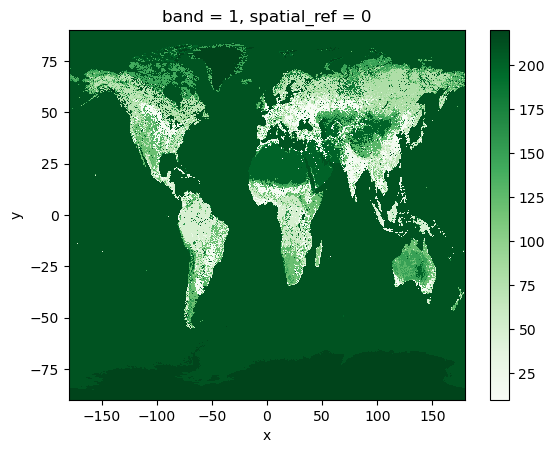

In [23]:
LCHansen20002.plot(cmap="Greens")

In [21]:
LCHansen20002needleleavedforest = (LCHansen20002 >= 70) & (LCHansen20002 <= 82)

In [28]:
LCHansen20002broadleavedforest = (LCHansen20002 >= 50) & (LCHansen20002 <= 62)

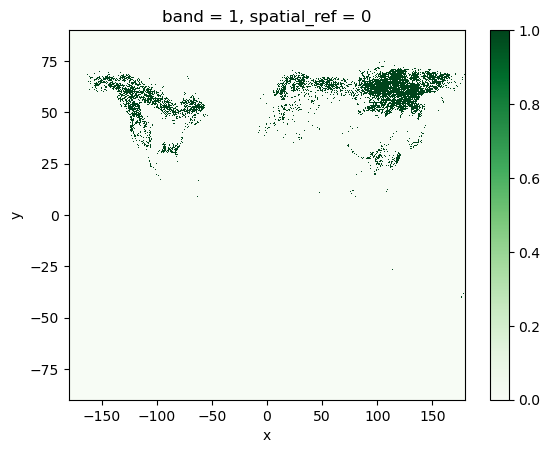

In [37]:
LCHansen20002needleleavedforest.plot(cmap="Greens")

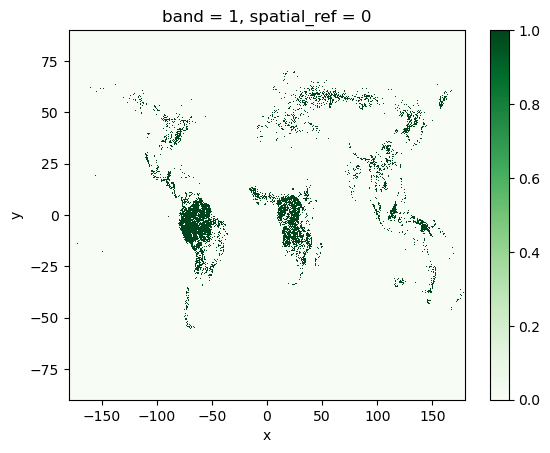

In [38]:
LCHansen20002broadleavedforest.plot(cmap="Greens")

## Select areas with snow and ice Hansen

In [22]:
maskLCHansen20002snow = (LCHansen20002 == 210)

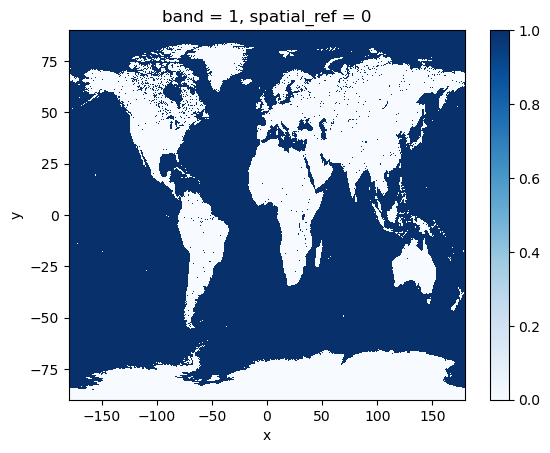

In [29]:
maskLCHansen20002snow.plot(cmap='Blues')

## GLC Select areas with forest

In [93]:
maskGLC_FCS302000E25N70band1 = (GLC_FCS302000E25N70band1 >= 70) & (GLC_FCS302000E25N70band1 <= 82)

In [26]:
maskGLC_FCS302000W155N65band1 = (GLC_FCS302000W155N65band1 >= 70) & (GLC_FCS302000W155N65band1 <= 82)

In [95]:
maskGLC_FCS302000W110N60band1 = (GLC_FCS302000W110N60band1 >= 70) & (GLC_FCS302000W110N60band1 <= 82)

In [25]:
maskGLC_FCS302000110W50Nband1 = (GLC_FCS302000110W50Nband1 >= 70) & (GLC_FCS302000110W50Nband1 <= 82)

## GLC Select areas with snow and ice

In [206]:
maskGLC_FCS302000E85N30band1 = (GLC_FCS302000E85N30band1 == 220)| (GLC_FCS302000E85N30band1 == 0)

In [207]:
maskGLC_FCS302000E5N50band1 = (GLC_FCS302000E5N50band1 == 220)| (GLC_FCS302000E5N50band1 == 0)

In [30]:
maskGLC_FCS30200010E50Nband1 = (GLC_FCS30200010E50Nband1 == 220) | (GLC_FCS30200010E50Nband1 == 0)

  grassland, 130
  sparse vegetation, 150
  flooded flat, 183
  saline, 184
  Impervious_surfaces, 190
  Bare_areas 200
  'Consolidated_bare_areas', 201
  Unconsolidated_bare_areas', 202
  'Water_body', 210
  'Permanent_ice_and_snow', 220
  'Filled_value' 0

# Mask Hansen E25 N70

In [96]:
bounds = GLC_FCS302000E25N70band1.rio.bounds()
print(bounds)

(25.0, 64.99979746553392, 30.000202534466077, 70.0)


In [97]:
maskLC_HansenE25N70 = LCHansen20002needleleavedforest.rio.clip_box(
    minx=25.0,
    miny=64.99979746553392,
    maxx=30.000202534466077,
    maxy=70.0
)

# Resample GLC E25 N70

In [98]:
maskGLC_FCS302000E25N70band1int = maskGLC_FCS302000E25N70band1.astype(int)

# Resample with interp

In [99]:
maskGLC_FCS302000E25N70band1int_interp = maskGLC_FCS302000E25N70band1int.interp(x = maskLC_HansenE25N70['x'], y = maskLC_HansenE25N70['y'], method='nearest')

In [100]:
maskGLC_FCS302000E25N70band1int_interp = maskGLC_FCS302000E25N70band1int_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

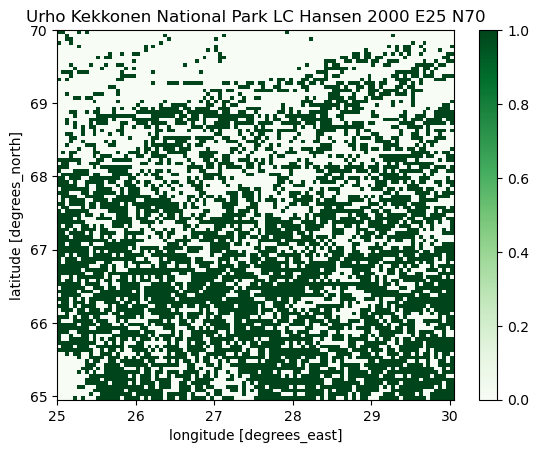

In [101]:
maskLC_HansenE25N70 = LCHansen20002needleleavedforest.rio.clip_box(
    minx=25.0,
    miny=64.99979746553392,
    maxx=30.000202534466077,
    maxy=70.0
)
maskLC_HansenE25N70.plot(cmap='Greens')
pyplot.title("Urho Kekkonen National Park LC Hansen 2000 E25 N70")
pyplot.savefig("C:/Users\/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Urho_Kekkonen_National_Park_LC_Hansen_2000_E25N70.png")

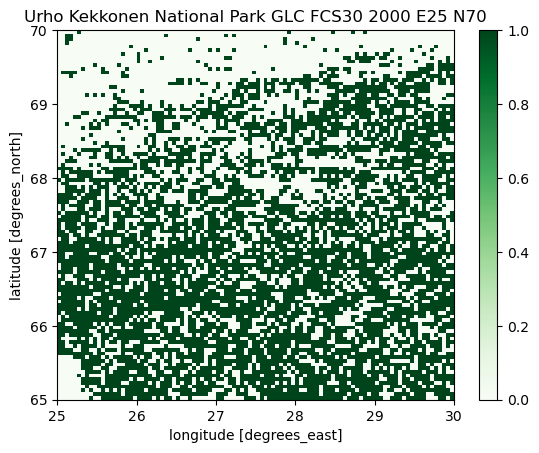

In [102]:
maskGLC_FCS302000E25N70band1int_interp.plot(cmap="Greens")
pyplot.title("Urho Kekkonen National Park GLC FCS30 2000 E25 N70")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Urho_Kekkonen_National_Park_GLC_FCS30_2000_E25N70.png")

# Compare the plots

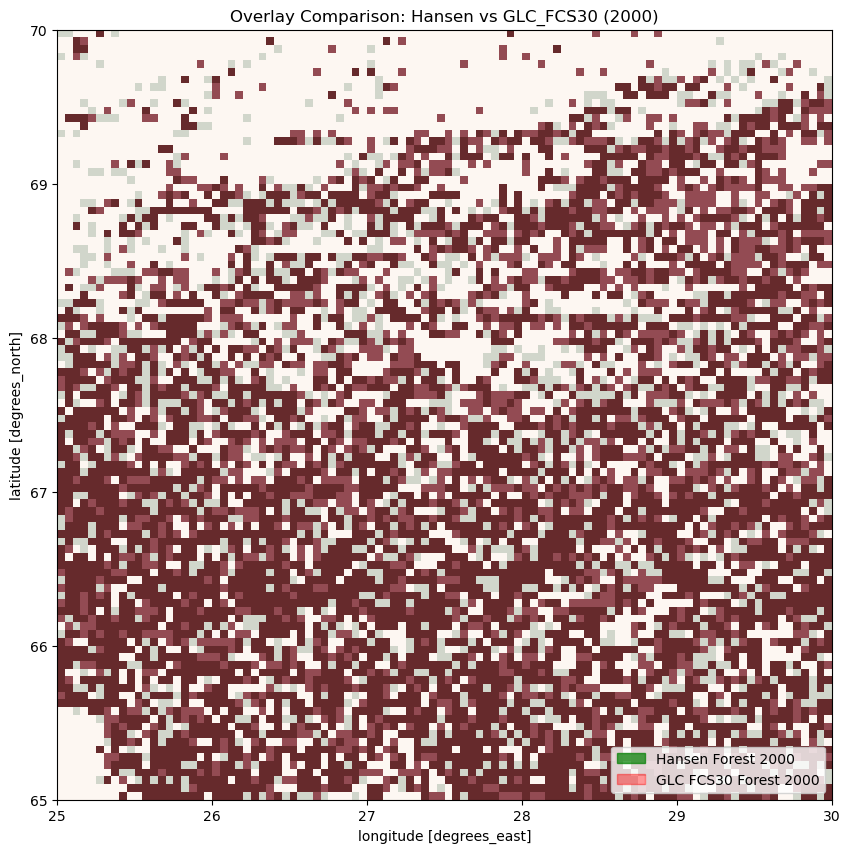

In [42]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE25N70.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000E25N70band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Urho_Kekkonen_National_Park_overlay_comparison_E25N70.png")
pyplot.show()

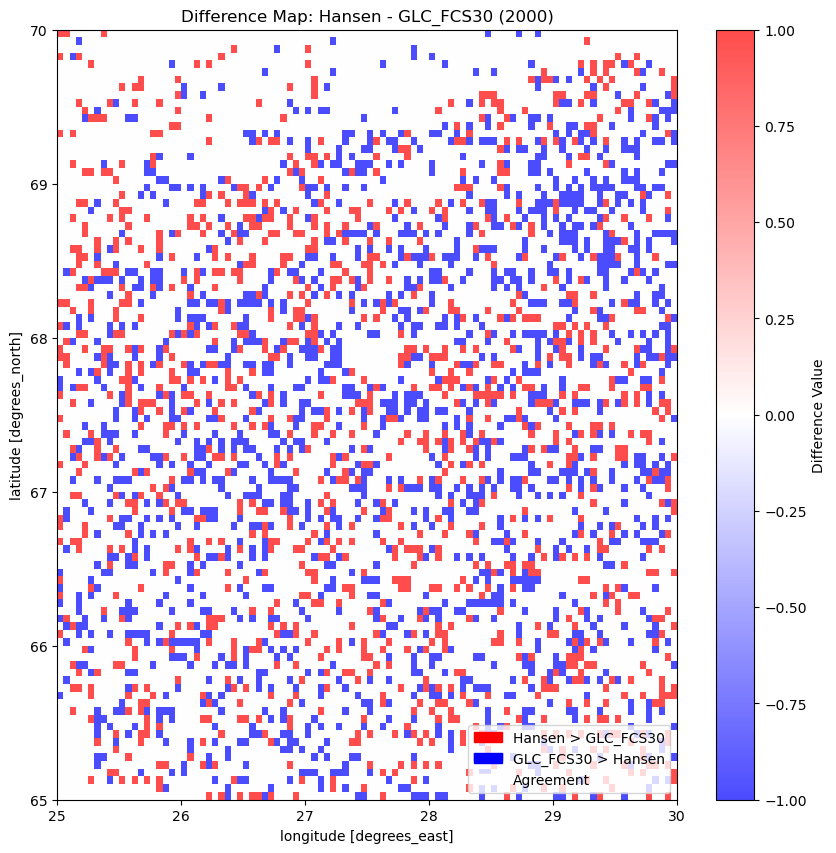

In [45]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000E25N70band1int_interp
    .rio.reproject_match(maskLC_HansenE25N70)
)

# Difference map
difference = maskLC_HansenE25N70 - mask_aligned
difference = difference.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Urho_Kekkonen_National_Park_difference_E25N70.png")
pyplot.show()

# Mask Hansen W110 N60

In [103]:
bounds = GLC_FCS302000W110N60band1.rio.bounds()
print(bounds)

(-110.0, 54.999797465533916, -104.99979746553392, 60.0)


Text(0.5, 1.0, 'C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Wood Buffalo National Park LC Hansen 2000 W110 N60')

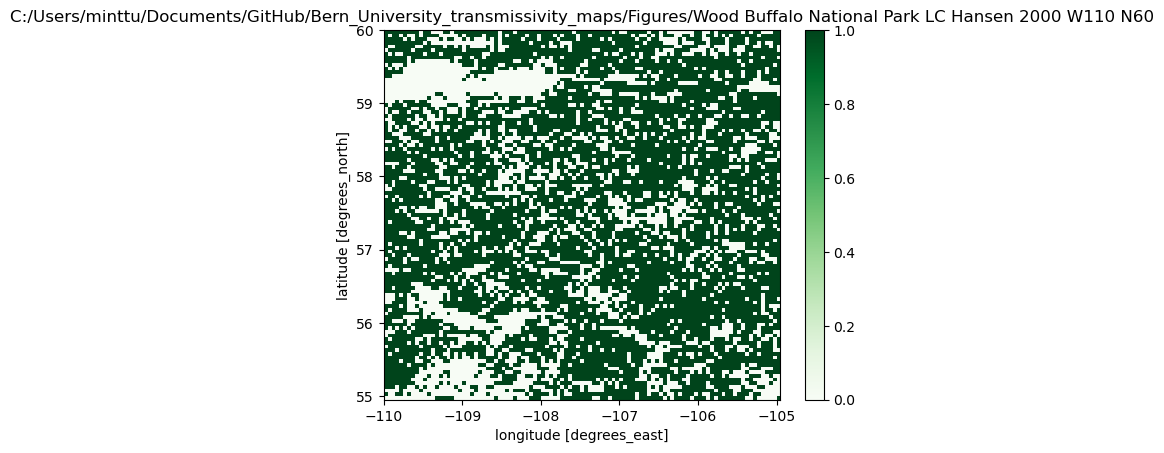

In [104]:
maskLC_HansenW110N60 = LCHansen20002needleleavedforest.rio.clip_box(
    minx=-110.0,
    miny=54.999797465533916,
    maxx=-104.99979746553392,
    maxy=60.0
)
maskLC_HansenW110N60.plot(cmap='Greens')
pyplot.title("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Wood Buffalo National Park LC Hansen 2000 W110 N60")

# Resample GLC W110 N60

In [105]:
maskGLC_FCS302000W110N60band1int = maskGLC_FCS302000W110N60band1.astype(int)

# Resample with interp

In [106]:
maskGLC_FCS302000W110N60band1int_interp = maskGLC_FCS302000W110N60band1int.interp(x = maskLC_HansenW110N60['x'], y = maskLC_HansenW110N60['y'], method='nearest')

In [107]:
maskGLC_FCS302000W110N60band1int_interp = maskGLC_FCS302000W110N60band1int_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

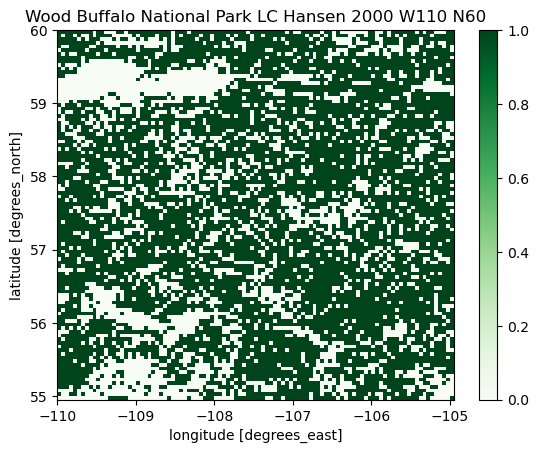

In [108]:
maskLC_HansenW110N60 = LCHansen20002needleleavedforest.rio.clip_box(
    minx=-110.0,
    miny=54.999797465533916,
    maxx=-104.99979746553392,
    maxy=60.0
)
maskLC_HansenW110N60.plot(cmap='Greens')
pyplot.title("Wood Buffalo National Park LC Hansen 2000 W110 N60")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Wood_Buffalo_National_Park_LC_Hansen_2000_W110N60.png")

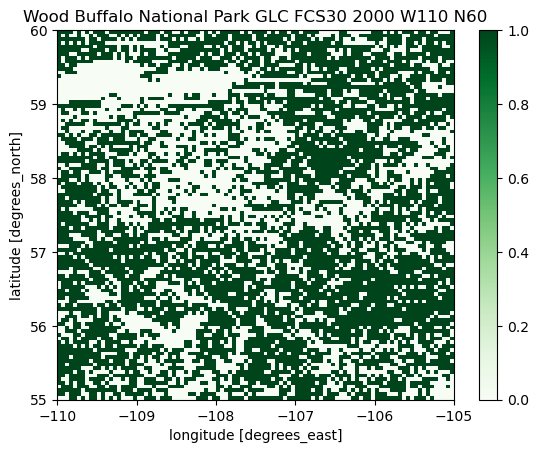

In [52]:
maskGLC_FCS302000W110N60band1int_interp.plot(cmap="Greens")
pyplot.title("Wood Buffalo National Park GLC FCS30 2000 W110 N60")
pyplot.savefig("Wood_Buffalo_National_Park_GLC_FCS30_2000_W110N60.png")

# Compare the plots

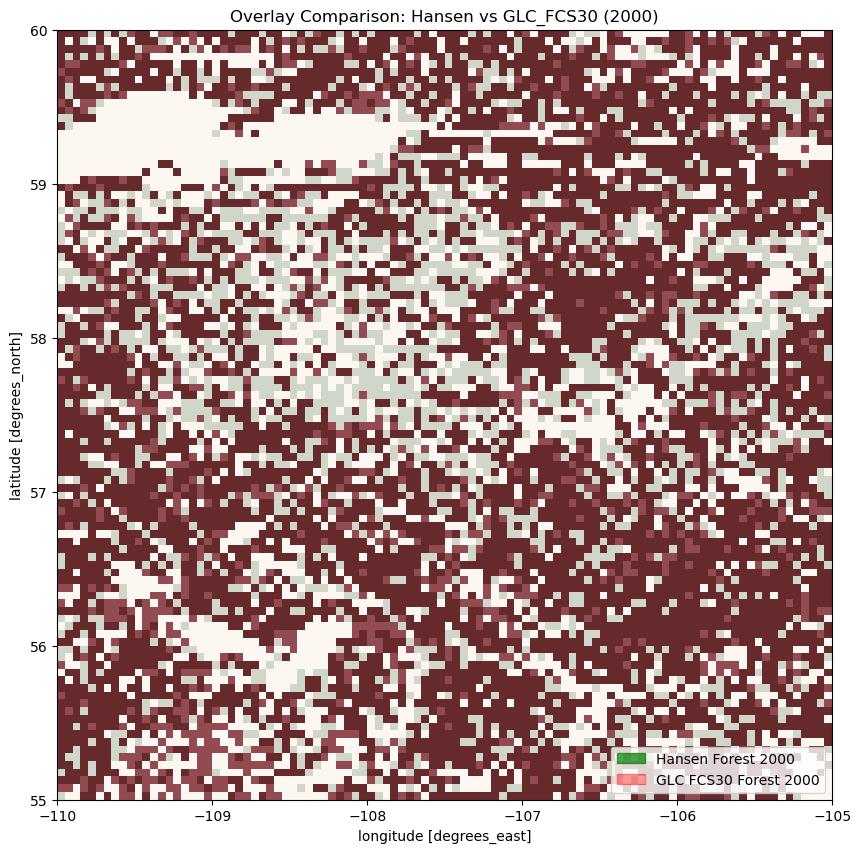

In [53]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenW110N60.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000W110N60band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Wood_Buffalo_National_Park_overlay_comparison_W110N60.png")
pyplot.show()

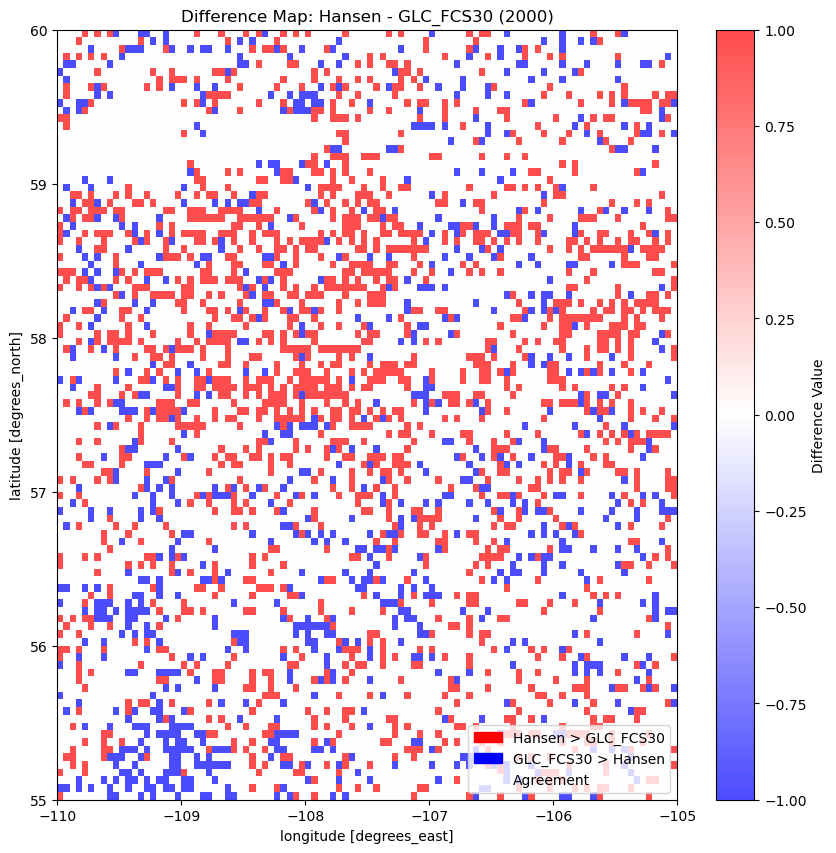

In [54]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000W110N60band1int_interp
    .rio.reproject_match(maskLC_HansenW110N60)
)

# Difference map
difference = maskLC_HansenW110N60 - mask_aligned
difference = difference.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Wood_Buffalo_National_Park_difference_W110N60.png")
pyplot.show()

# Mask E85 N30

In [209]:
bounds = GLC_FCS302000E85N30band1.rio.bounds()
print(bounds)

(85.0, 24.999797465533923, 90.00020253446608, 30.0)


Text(0.5, 1.0, 'C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mount Everest LC Hansen 2000 E85 N30')

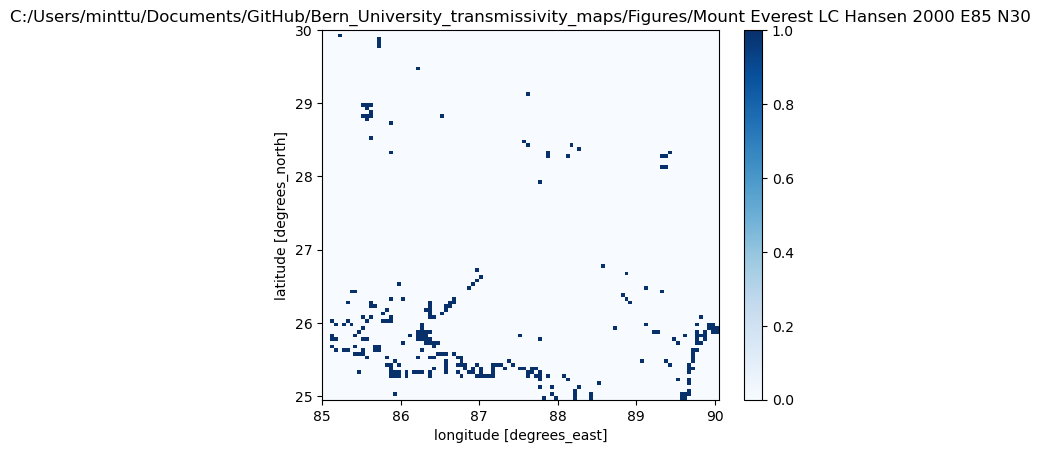

In [210]:
maskLC_HansenE85N30 = maskLCHansen20002snow.rio.clip_box(
    minx=85.0,
    miny=24.999797465533923,
    maxx=90.00020253446608,
    maxy=30.0
)
maskLC_HansenE85N30.plot(cmap='Blues')
pyplot.title("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mount Everest LC Hansen 2000 E85 N30")

# Resample GLC E85 N30

In [211]:
maskGLC_FCS302000E85N30band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False,  True],
       [False, False, False, ..., False, False,  True],
       [ True,  True,  True, ...,  True,  True,  True]],
      shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 30.0 30.0 30.0 30.0 ... 25.0 25.0 25.0 25.0
  * x            (x) float64 148kB 85.0 85.0 85.0 85.0 ... 90.0 90.0 90.0 90.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [212]:
maskGLC_FCS302000E85N30band1int = maskGLC_FCS302000E85N30band1.astype(int)

In [59]:
maskGLC_FCS302000E85N30band1int

<xarray.DataArray (y: 18554, x: 18554)> Size: 3GB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 30.0 30.0 30.0 30.0 ... 25.0 25.0 25.0 25.0
  * x            (x) float64 148kB 85.0 85.0 85.0 85.0 ... 90.0 90.0 90.0 90.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

# Resample with interp

In [213]:
croppedLCHansen2000E85N30 = LCHansen20002.rio.clip_box(
    minx=85.0,
    miny=24.999797465533923,
    maxx=90.00020253446608,
    maxy=30.0
)

In [214]:
maskGLC_FCS302000E85N30band1int_interp = maskGLC_FCS302000E85N30band1int.interp(x = croppedLCHansen2000E85N30['x'], y = croppedLCHansen2000E85N30['y'], method='nearest')

In [215]:
maskGLC_FCS302000E85N30band1int_interp = maskGLC_FCS302000E85N30band1int_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Plot E85 N30

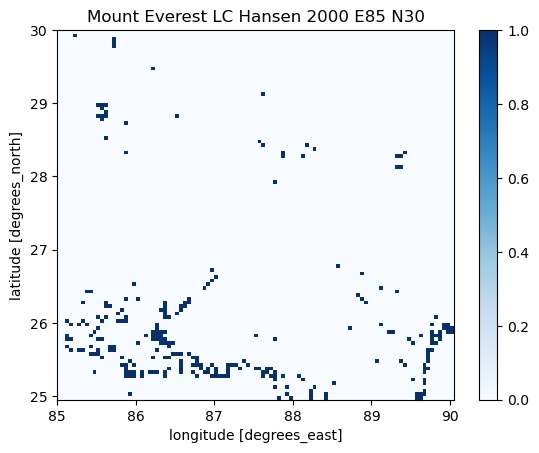

In [216]:
maskLC_HansenE85N30 = maskLCHansen20002snow.rio.clip_box(
    minx=85.0,
    miny=24.999797465533923,
    maxx=90.00020253446608,
    maxy=30.0
)
maskLC_HansenE85N30.plot(cmap='Blues')
pyplot.title("Mount Everest LC Hansen 2000 E85 N30")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mount_everest_LC_Hansen_2000_E85N30.png")

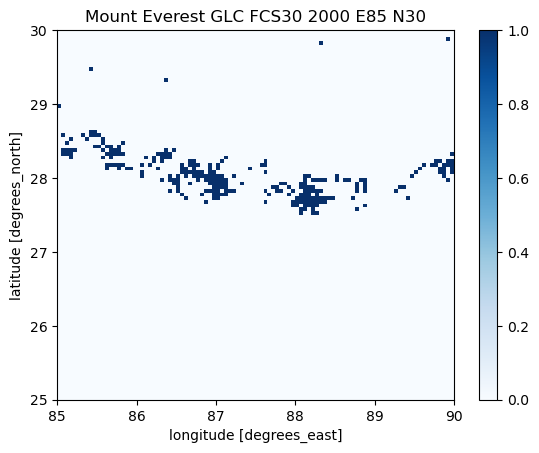

In [64]:
maskGLC_FCS302000E85N30band1int_interp.plot(cmap="Blues")
pyplot.title("Mount Everest GLC FCS30 2000 E85 N30")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mount_everest_GLC_FCS30_2000_E85N30.png")

# Compare the plots

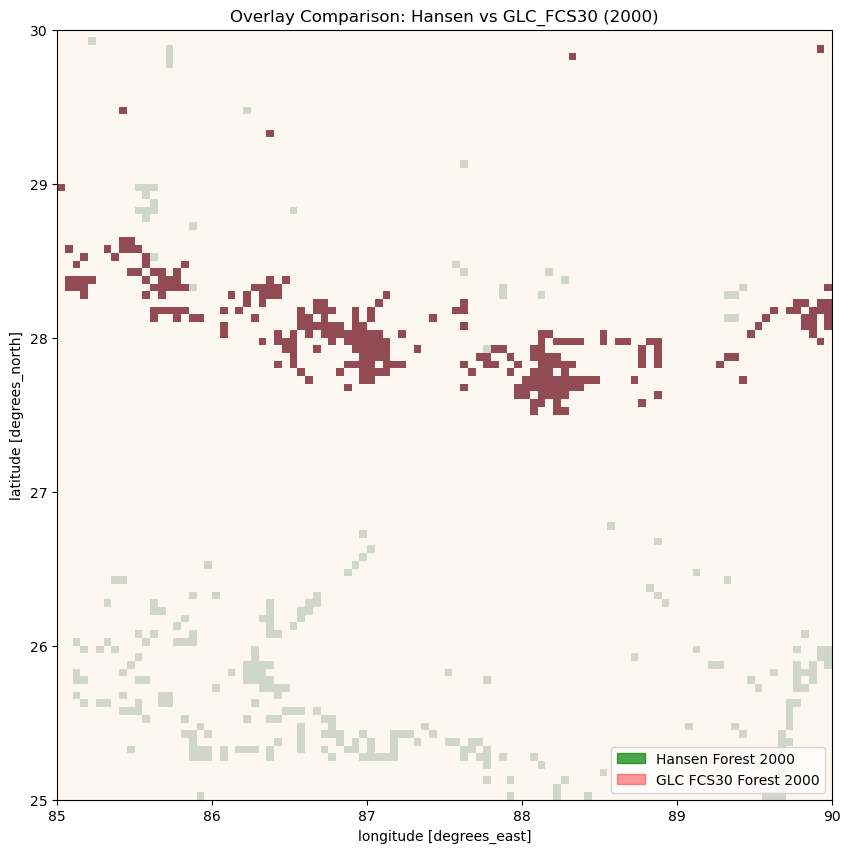

In [65]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE85N30.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000E85N30band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mount_everest_overlay_comparison_E85N30.png")
pyplot.show()

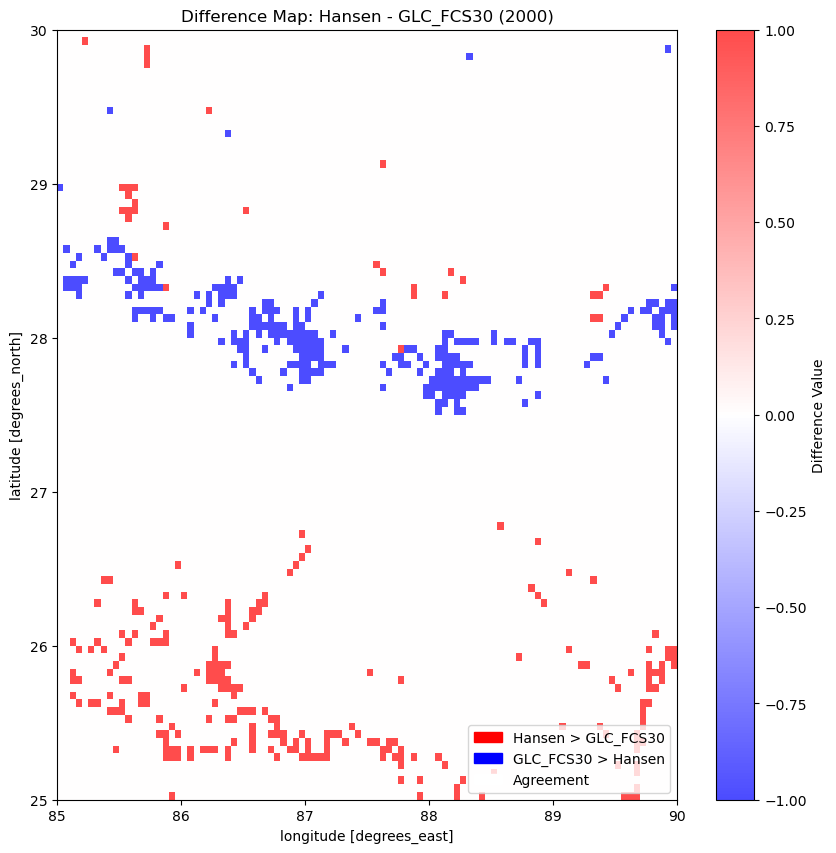

In [66]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000E85N30band1int_interp
    .rio.reproject_match(maskLC_HansenE85N30)
)

# Difference map
difference = maskLC_HansenE85N30 - mask_aligned
difference = difference.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mount_everest_difference_E85N30.png")
pyplot.show()

# Mask E5N 50

In [98]:
bounds = GLC_FCS302000E5N50band1.rio.bounds()
print(bounds)

(5.0, 44.999797465533916, 10.00020253446608, 50.0)


Text(0.5, 1.0, 'Mont Blanc LC Hansen 2000 E5 N50')

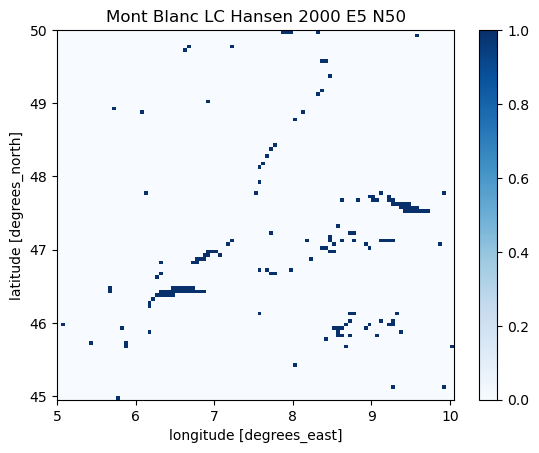

In [217]:
maskLC_HansenE5N50 = maskLCHansen20002snow.rio.clip_box(
    minx=5.0,
    miny=44.999797465533916,
    maxx=10.00020253446608,
    maxy=50.0
)
maskLC_HansenE5N50.plot(cmap='Blues')
pyplot.title("Mont Blanc LC Hansen 2000 E5 N50")

In [218]:
maskGLC_FCS302000E5N50band1int = maskGLC_FCS302000E5N50band1.astype(int)

# Resample with interp

In [219]:
croppedLCHansen2000E5N50 = maskLCHansen20002snow.rio.clip_box(
    minx=5.0,
    miny=44.999797465533916,
    maxx=10.00020253446608,
    maxy=50.0
)

In [220]:
maskGLC_FCS302000E5N505band1int_interp = maskGLC_FCS302000E5N50band1int.interp(x = croppedLCHansen2000E5N50['x'], y = croppedLCHansen2000E5N50['y'], method='nearest')

In [221]:
maskGLC_FCS302000E5N505band1int_interp = maskGLC_FCS302000E5N505band1int_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

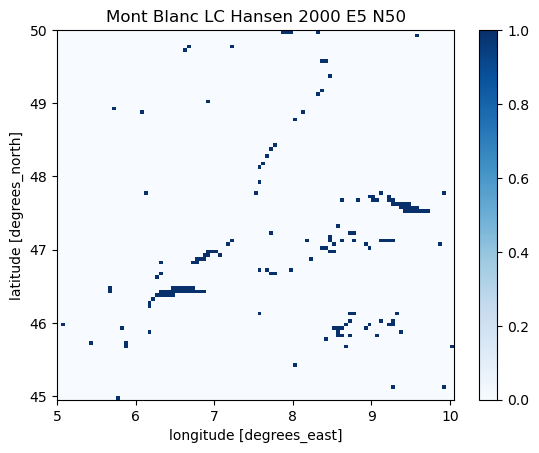

In [222]:
croppedLCHansen2000E5N50.plot(cmap='Blues')
pyplot.title("Mont Blanc LC Hansen 2000 E5 N50")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mont_Blanc_LC_Hansen_2000_E5N50.png")

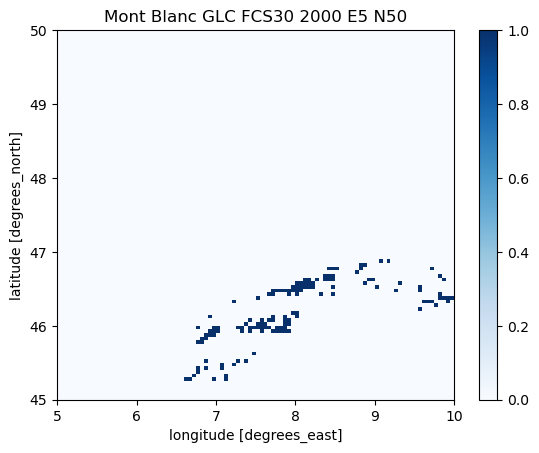

In [105]:
maskGLC_FCS302000E5N505band1int_interp.plot(cmap="Blues")
pyplot.title("Mont Blanc GLC FCS30 2000 E5 N50")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mont_Blanc_GLCS30_2000_E5N50.png")

# Compare the plots

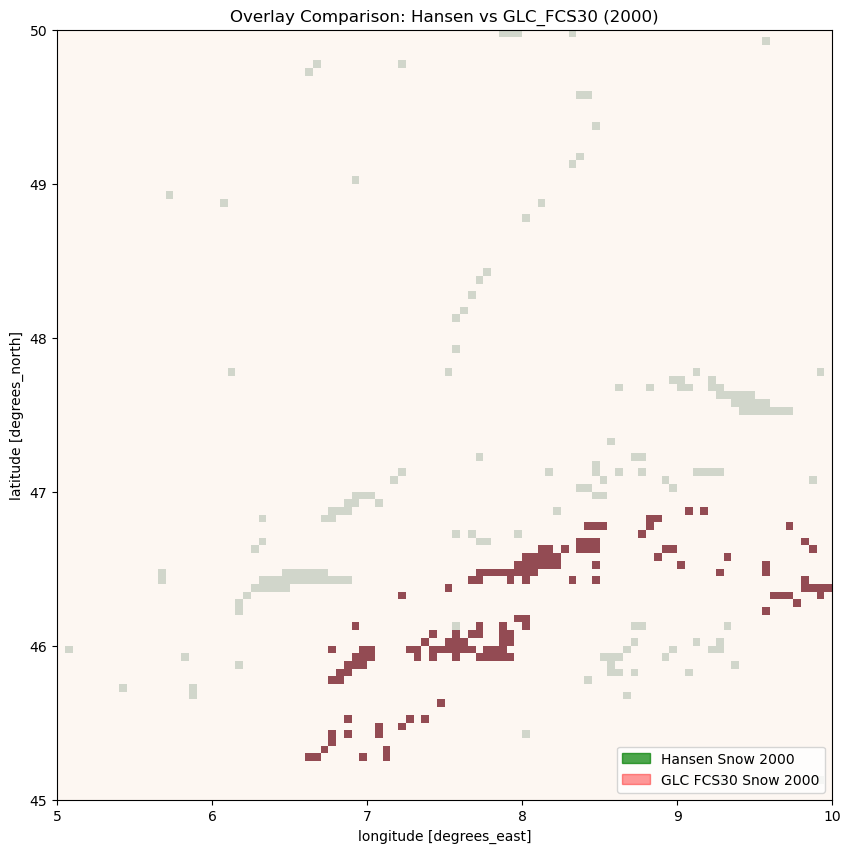

In [75]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE5N50.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000E5N505band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Snow 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Snow 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mont_Blanc_overlay_comparison_E5N50.png")
pyplot.show()

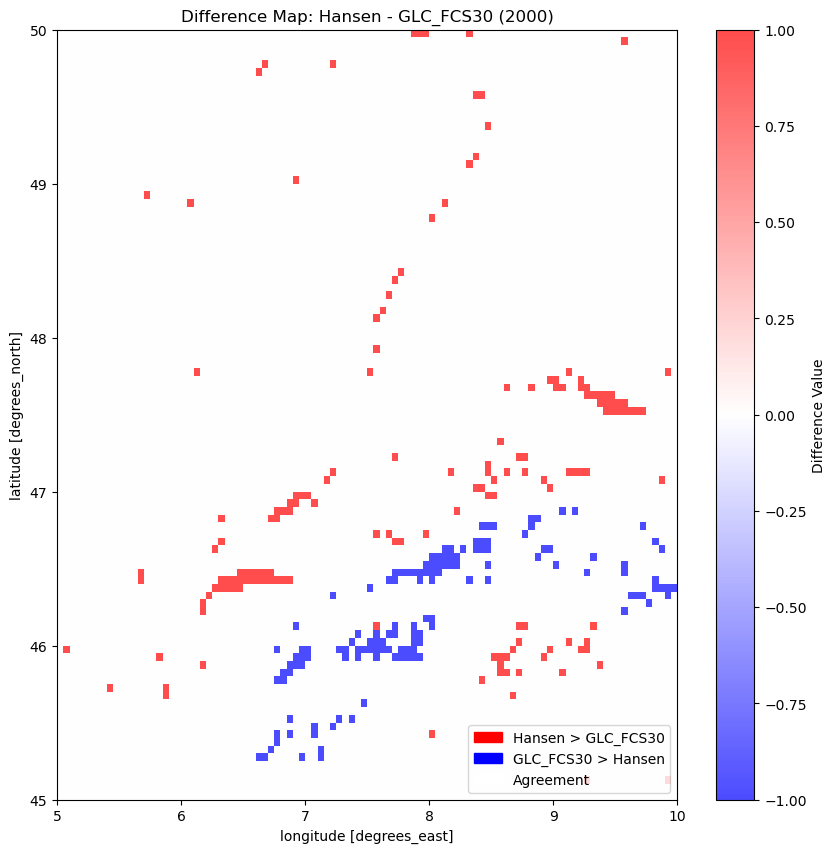

In [76]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000E5N505band1int_interp
    .rio.reproject_match(maskLC_HansenE5N50)
)

# Difference map
difference = maskLC_HansenE5N50 - mask_aligned
difference = difference.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Mont_Blanc_difference_E5N50.png")
pyplot.show()

# Mask Hansen E10 N50

In [31]:
bounds = GLC_FCS30200010E50Nband1.rio.bounds()
print(bounds)

(10.0, 44.999797465533916, 15.00020253446608, 50.0)


Text(0.5, 1.0, 'Alps LC Hansen 2000 E10 N50')

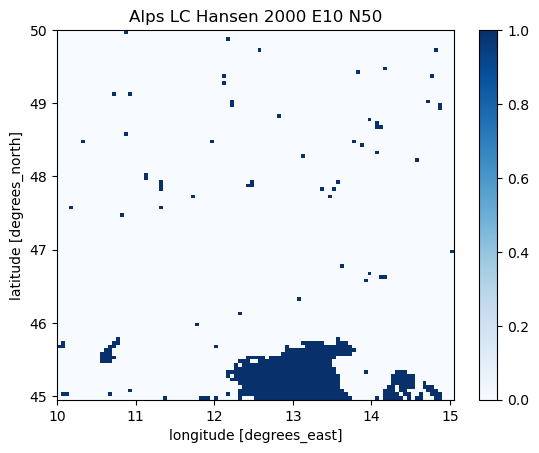

In [32]:
maskLC_HansenE10N50 = maskLCHansen20002snow.rio.clip_box(
    minx=10.0,
    miny=44.999797465533916,
    maxx=15.00020253446608,
    maxy=50.0
)
maskLC_HansenE10N50.plot(cmap='Blues')
pyplot.title("Alps LC Hansen 2000 E10 N50")

# Resample E10 N50

In [33]:
maskGLC_FCS30200010E50Nband11int = maskGLC_FCS30200010E50Nband1.astype(int)

In [34]:
maskGLC_FCS30200010E50Nband1_interp = maskGLC_FCS30200010E50Nband11int.interp(x = maskLC_HansenE10N50['x'], y = maskLC_HansenE10N50['y'], method='nearest')

In [35]:
maskGLC_FCS30200010E50Nband1_interp = maskGLC_FCS30200010E50Nband1_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Plot E10 N50

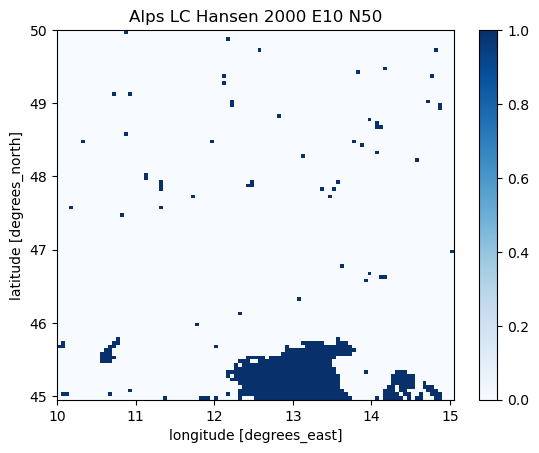

In [36]:
maskLC_HansenE10N50.plot(cmap='Blues')
pyplot.title("Alps LC Hansen 2000 E10 N50")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alps_LC_Hansen_E10N50.png")

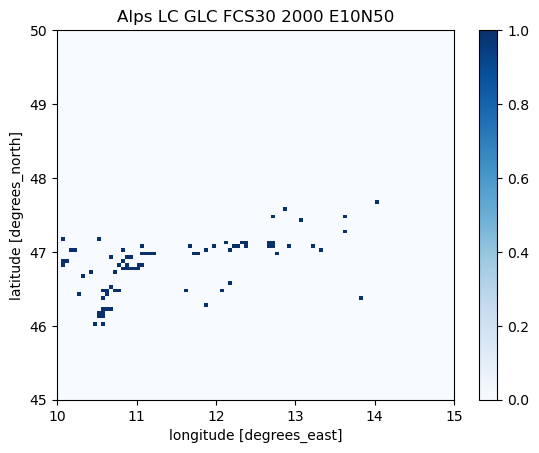

In [112]:
maskGLC_FCS30200010E50Nband1_interp.plot(cmap="Blues")
pyplot.title("Alps LC GLC FCS30 2000 E10N50")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alps_GLC_FCS30_E10N50.png")

# Compare the plots

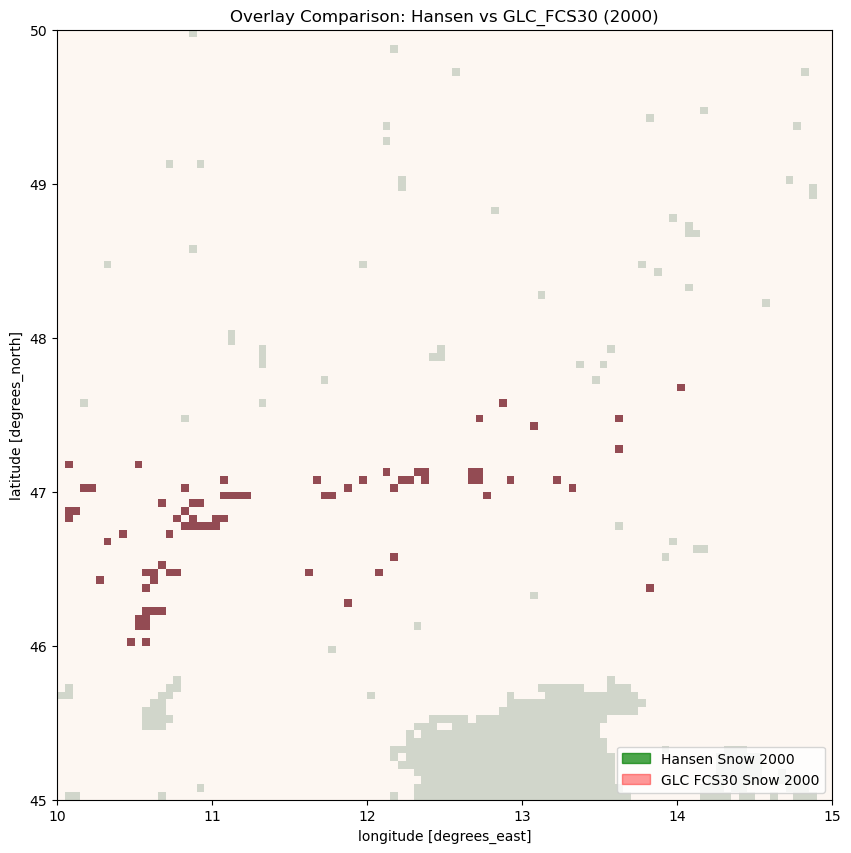

In [113]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE10N50.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS30200010E50Nband1_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Snow 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Snow 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alps_overlay_comparison_E10N50.png")
pyplot.show()

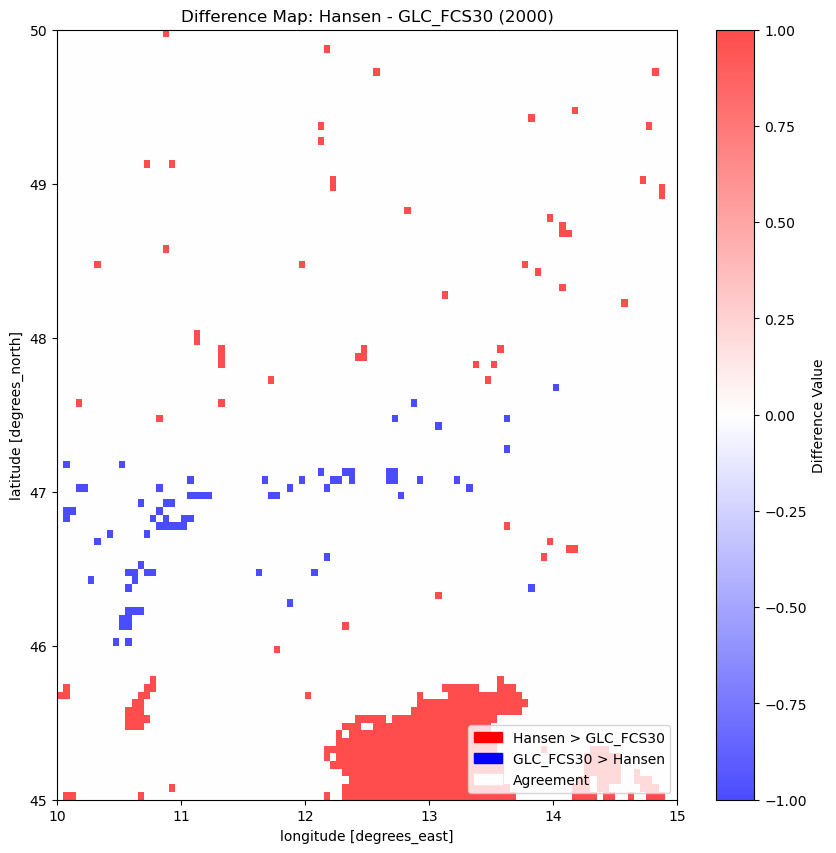

In [114]:
# Align grids
mask_aligned = (
    maskGLC_FCS30200010E50Nband1_interp
    .rio.reproject_match(maskLC_HansenE10N50)
)

# Difference map
difference = maskLC_HansenE10N50 - mask_aligned
difference = difference.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alps_difference_E10N50.png")
pyplot.show()

# Mask W110 N50

In [37]:
bounds = GLC_FCS302000110W50Nband1.rio.bounds()
print(bounds)

(-110.0, 44.999797465533916, -104.99979746553392, 50.0)


In [38]:
maskLC_HansenW110N50 = LCHansen20002needleleavedforest.rio.clip_box(
    minx=-110.0,
    miny=44.999797465533916,
    maxx=-104.99979746553392,
    maxy=50.0
)

# Resample W110 N50

In [39]:
maskGLC_FCS302000110W50Nband1int = maskGLC_FCS302000110W50Nband1.astype(int)

In [40]:
maskGLC_FCS302000110W50Nband1_interp = maskGLC_FCS302000110W50Nband1int.interp(x = maskLC_HansenW110N50['x'], y = maskLC_HansenW110N50['y'], method='nearest')

In [41]:
maskGLC_FCS302000110W50Nband1_interp = maskGLC_FCS302000110W50Nband1_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Plot W110 N50

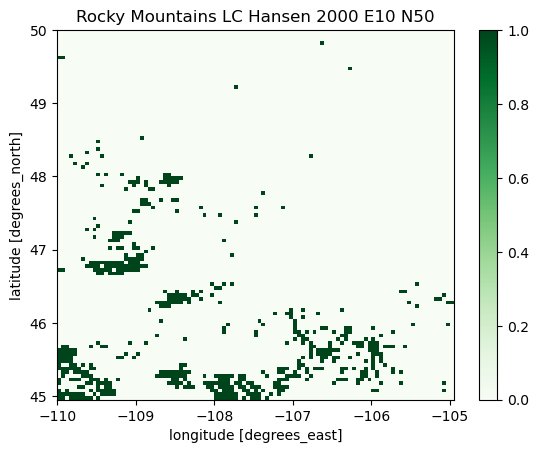

In [42]:
maskLC_HansenW110N50.plot(cmap='Greens')
pyplot.title("Rocky Mountains LC Hansen 2000 E10 N50")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Rocky_Mountains_LC_Hansen_W110N50.png")

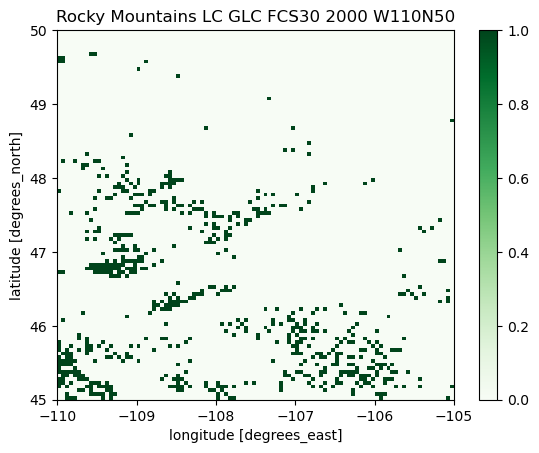

In [38]:
maskGLC_FCS302000110W50Nband1_interp.plot(cmap="Greens")
pyplot.title("Rocky Mountains LC GLC FCS30 2000 W110N50")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Rocky_Mountains_GLC_FCS30_W110N50.png")

# Compare the plots

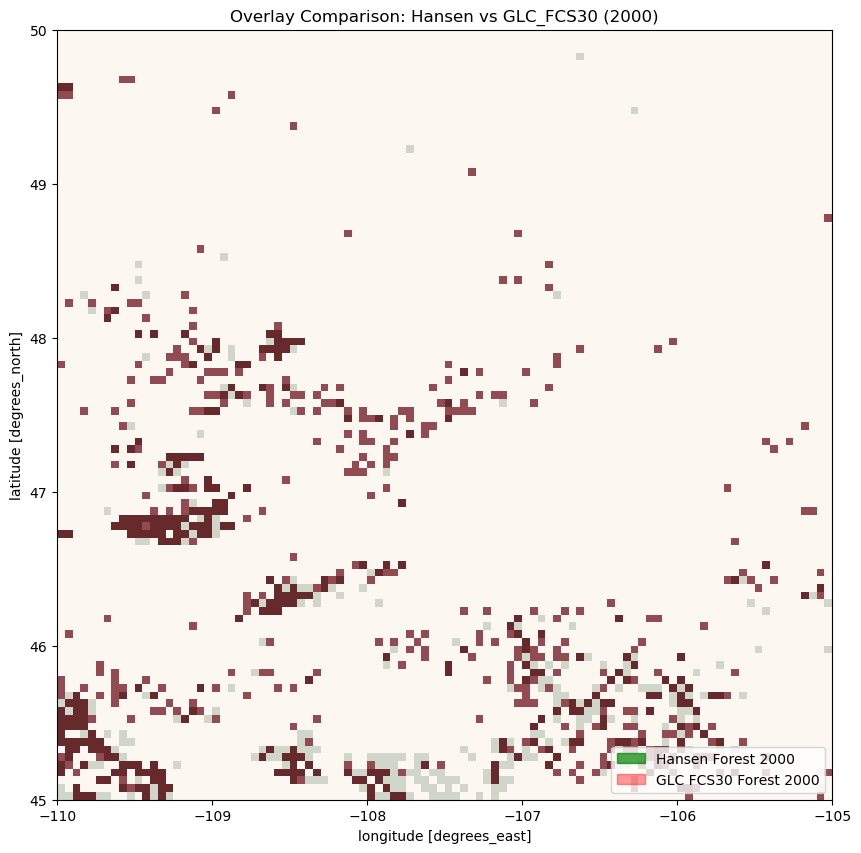

In [46]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenW110N50.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000110W50Nband1_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Rocky_Mountains_overlay_comparison_W110N50.png")
pyplot.show()

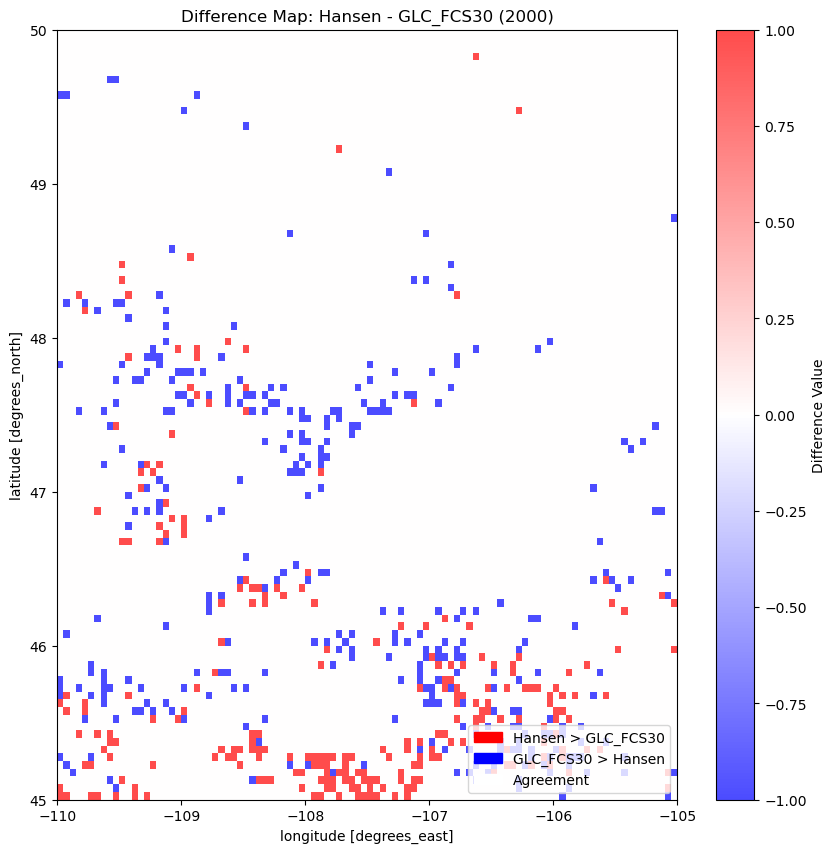

In [45]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000110W50Nband1_interp
    .rio.reproject_match(maskLC_HansenW110N50)
)

# Difference map
difference = maskLC_HansenW110N50 - mask_aligned
difference = difference.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)


# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Rocky_Mountains_difference_W110N50.png")
pyplot.show()

# Mask W155 N65

In [43]:
bounds = GLC_FCS302000W155N65band1.rio.bounds()
print(bounds)

(-155.0, 59.999797465533916, -149.99979746553393, 65.0)


In [44]:
maskLC_HansenW155N65 = LCHansen20002needleleavedforest.rio.clip_box(
    minx=-155.0,
    miny=59.999797465533916,
    maxx=-149.99979746553393,
    maxy=65.0
)

# Resample W155 N65

In [45]:
maskGLC_FCS302000W155N65band1int = maskGLC_FCS302000W155N65band1.astype(int)

In [46]:
maskGLC_FCS302000W155N65band1int

<xarray.DataArray (y: 18554, x: 18554)> Size: 3GB
array([[0, 0, 0, ..., 1, 0, 0],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 65.0 65.0 65.0 65.0 ... 60.0 60.0 60.0 60.0
  * x            (x) float64 148kB -155.0 -155.0 -155.0 ... -150.0 -150.0 -150.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [47]:
maskGLC_FCS302000W155N65band_interp = maskGLC_FCS302000W155N65band1int.interp(x = maskLC_HansenW155N65['x'], y = maskLC_HansenW155N65['y'], method='nearest')

In [48]:
maskGLC_FCS302000W155N65band_interp = maskGLC_FCS302000W155N65band_interp.isel(
    y=slice(None, -1),   # remove last row
    x=slice(None, -1)    # remove last column
)

# Plot W155 N65

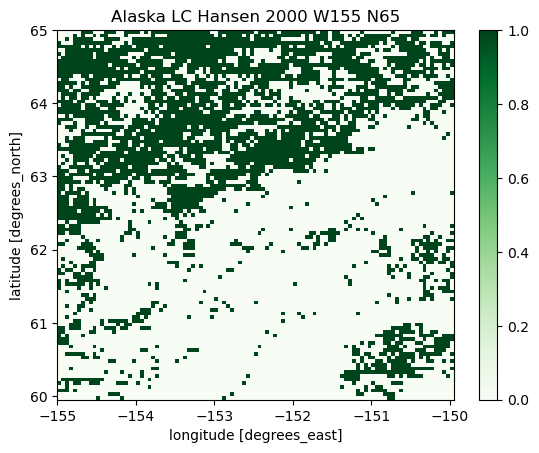

In [49]:
maskLC_HansenW155N65.plot(cmap='Greens')
pyplot.title("Alaska LC Hansen 2000 W155 N65")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alaska_LC_Hansen_W155N65.png")

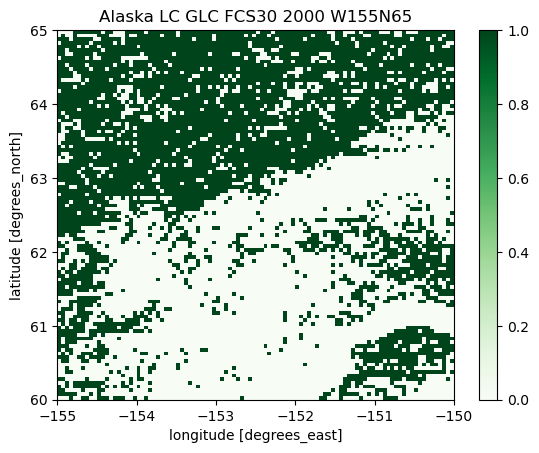

In [31]:
maskGLC_FCS302000W155N65band_interp.plot(cmap="Greens")
pyplot.title("Alaska LC GLC FCS30 2000 W155N65")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alaska_GLC_FCS30_W155N65.png")

# Compare the plots

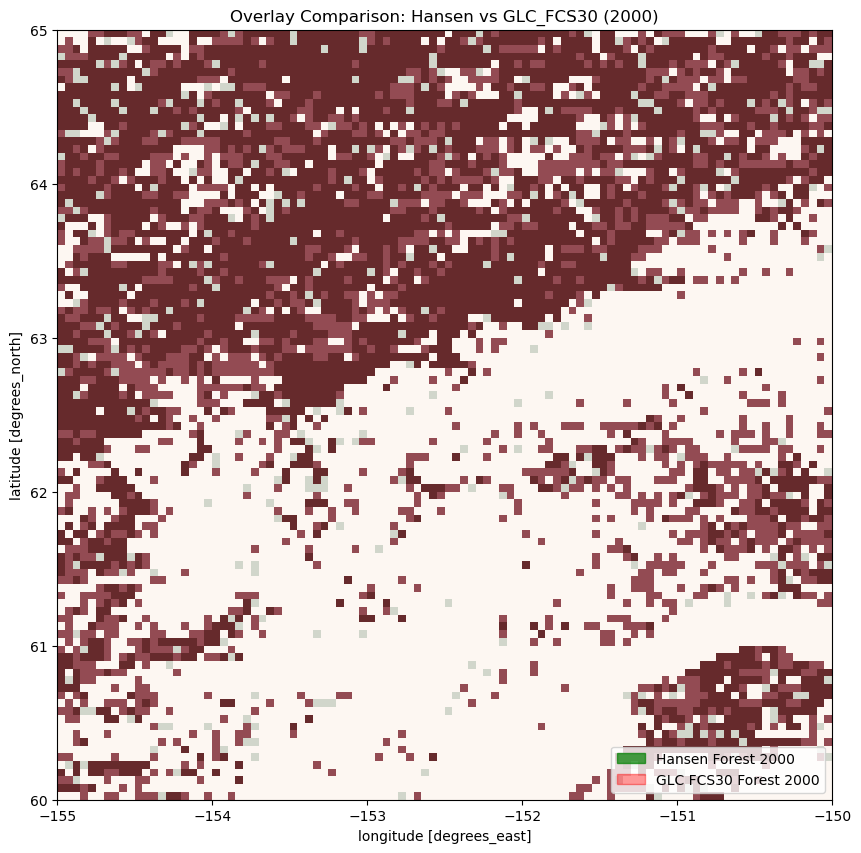

In [47]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenW155N65.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000W155N65band_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alaska_overlay_comparison_W155N65.png")
pyplot.show()

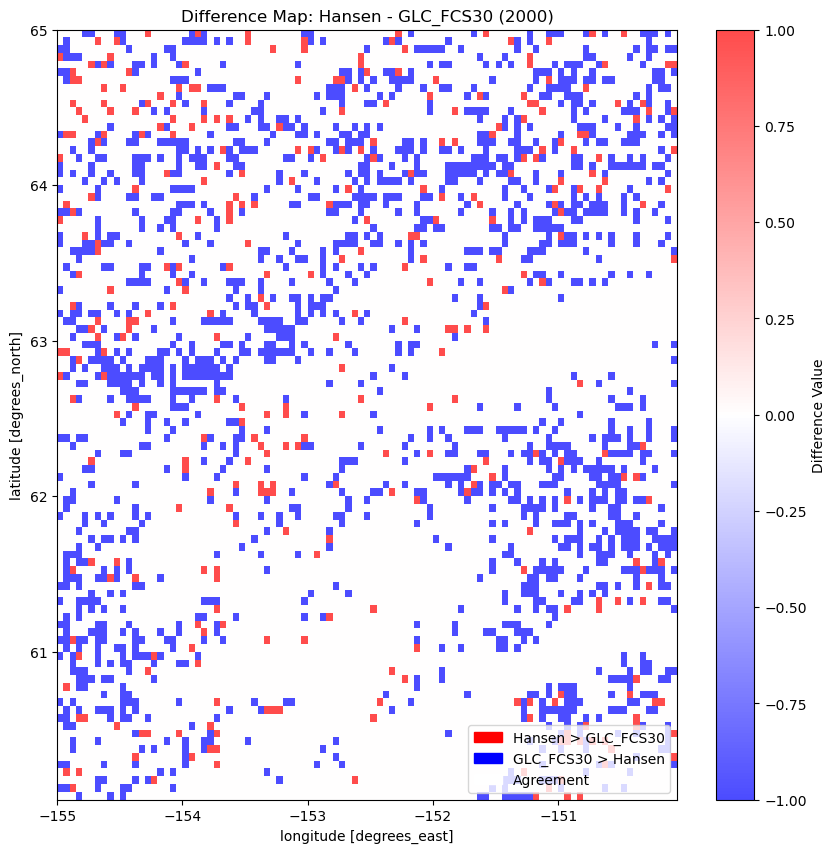

In [327]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000W155N65band_interp
    .rio.reproject_match(maskLC_HansenW155N65)
)

# Difference map
difference = maskLC_HansenW155N65 - mask_aligned

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")
pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Alaska_difference_W155N65.png")
pyplot.show()

# Compare the LC maps

In [50]:
resultsf = pd.DataFrame(columns=["E25N70", "W110N60", "W155N65", "W110N50"], index = ["same", "different", "difference in forest"])

In [110]:
resultss = pd.DataFrame(columns=["E85N30", "E5N50", "E10N50"], index = ["same", "different", "difference in snow"])

## E25N70

In [121]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interp.values

In [122]:
maskLC_HansenE25N701 = maskLC_HansenE25N70.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [123]:
maskLC_HansenE25N70arr = maskLC_HansenE25N701.values.astype(int)

## W110N60

In [124]:
maskGLC_FCS302000W110N60band1int_interparr = maskGLC_FCS302000W110N60band1int_interp.values

In [125]:
maskLC_HansenW110N601 = maskLC_HansenW110N60.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [126]:
maskLC_HansenW110N60arr = maskLC_HansenW110N601.values.astype(int)

# E85N30

In [111]:
maskGLC_FCS302000E85N30band1int_interparr = maskGLC_FCS302000E85N30band1int_interp.values

NameError: name 'maskGLC_FCS302000E85N30band1int_interp' is not defined

In [233]:
maskLC_HansenE85N301 = maskLC_HansenE85N30.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [234]:
maskLC_HansenE85N30arr = maskLC_HansenE85N301.values.astype(int)

# E5N50

In [235]:
maskGLC_FCS302000E5N50band1int_interparr = maskGLC_FCS302000E5N505band1int_interp.values

In [236]:
maskLC_HansenE5N501 = maskLC_HansenE5N50.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [237]:
maskLC_HansenE5N50arr = maskLC_HansenE5N501.values.astype(int)

# E10N50

In [52]:
maskGLC_FCS30200010E50Nband1_interparr = maskGLC_FCS30200010E50Nband1_interp.values

In [53]:
maskLC_HansenE10N50 = maskLC_HansenE10N50.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [54]:
maskLC_HansenE10N50arr = maskLC_HansenE10N50.values.astype(int)

# W110N50

In [55]:
maskGLC_FCS302000110W50Nband1_interparr = maskGLC_FCS302000110W50Nband1_interp.values

In [56]:
maskGLC_FCS302000110W50Nband1_interparr

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 1., 0.]], shape=(100, 100))

In [57]:
maskLC_HansenW110N50 = maskLC_HansenW110N50.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [58]:
maskLC_HansenW110N50arr = maskLC_HansenW110N50.values.astype(int)

# W155N65

In [59]:
maskGLC_FCS302000W155N65band1int_interparr = maskGLC_FCS302000W155N65band_interp.values

In [60]:
maskLC_HansenW155N65 = maskLC_HansenW155N65.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [61]:
maskLC_HansenW155N65arr = maskLC_HansenW155N65.values.astype(int)

# Count differences

## E25N70

In [390]:
differences = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr != maskLC_HansenE25N70arr))

In [391]:
same = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == maskLC_HansenE25N70arr))

In [392]:
all = differences+same

In [393]:
Forest = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == 1))

In [394]:
Forest2 = int(np.sum(maskLC_HansenE25N70arr == 1))

In [395]:
all = differences+same

In [396]:
same/all*100

72.1

In [397]:
differences/all*100

27.900000000000002

In [398]:
(Forest-Forest2)/all*100

3.56

In [95]:
resultsf.at['same', 'E25N70'] = 72.1

In [96]:
resultsf.at['different', 'E25N70'] = 27.900000000000002

In [97]:
resultsf.at['difference in forest', 'E25N70'] = 3.56

## W110N60

In [402]:
differences = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr != maskLC_HansenW110N60arr))

In [403]:
same = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr == maskLC_HansenW110N60arr))

In [404]:
all = differences+same

In [405]:
Forest = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr == 1))

In [406]:
Forest2 = int(np.sum(maskLC_HansenW110N60arr))

In [407]:
all = differences+same

In [408]:
same/all*100

72.1

In [409]:
differences/all*100

27.900000000000002

In [410]:
(Forest-Forest2)/all*100

-8.38

In [98]:
resultsf.at['same', 'W110N60'] = 72.1

In [99]:
resultsf.at['different', 'W110N60'] = 27.900000000000002

In [100]:
resultsf.at['difference in forest', 'W110N60'] = -8.38

# E85N25

In [414]:
differences = int(np.sum(maskGLC_FCS302000E85N30band1int_interparr != maskLC_HansenE85N30arr))

In [415]:
same = int(np.sum(maskGLC_FCS302000E85N30band1int_interparr == maskLC_HansenE85N30arr))

In [416]:
snow = int(np.sum(maskGLC_FCS302000E85N30band1int_interparr == 1))

In [417]:
snow2 = int(np.sum(maskLC_HansenE85N30arr == 1))

In [418]:
all = differences+same

In [419]:
same/all*100

94.89999999999999

In [420]:
differences/all*100

5.1

In [421]:
(snow-snow2)/all*100

0.08

In [112]:
resultss.at['same', 'E85N30'] = 94.89999999999999

In [113]:
resultss.at['different', 'E85N30'] = 5.1

In [114]:
resultss.at['difference in snow', 'E85N30'] = 0.08

# E5N50

In [115]:
differences = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr != maskLC_HansenE5N50arr))

NameError: name 'maskGLC_FCS302000E5N50band1int_interparr' is not defined

In [ ]:
same = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr == maskLC_HansenE5N50arr))

In [427]:
snow = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr == 1))

In [428]:
snow2 = int(np.sum(maskLC_HansenE5N50arr == 1))

In [429]:
all = differences+same

In [430]:
same/all*100

97.09

In [431]:
differences/all*100

2.91

In [432]:
(snow-snow2)/all*100

-0.22999999999999998

In [116]:
resultss.at['same', 'E5N50'] = 97.09

In [117]:
resultss.at['different', 'E5N50'] = 2.91

In [118]:
resultss.at['difference in snow', 'E5N50'] = -0.22999999999999998

# E10N50

In [119]:
differences = int(np.sum(maskGLC_FCS30200010E50Nband1_interparr != maskLC_HansenE10N50arr))

In [120]:
same = int(np.sum(maskGLC_FCS30200010E50Nband1_interparr == maskLC_HansenE10N50arr))

In [121]:
snow = int(np.sum(maskGLC_FCS30200010E50Nband1_interparr == 1))

In [122]:
snow2 = int(np.sum(maskLC_HansenE10N50arr == 1))

In [123]:
all = differences+same

In [124]:
same/all*100

94.51

In [125]:
differences/all*100

5.489999999999999

In [126]:
(snow-snow2)/all*100

-3.95

In [127]:
resultss.at['same', 'E10N50'] = same/all*100

In [128]:
resultss.at['different', 'E10N50'] = differences/all*100

In [129]:
resultss.at['difference in snow', 'E10N50'] = (snow-snow2)/all*100

# W110N50

In [73]:
differences = int(np.sum(maskGLC_FCS302000110W50Nband1_interparr != maskLC_HansenW110N50arr))

In [74]:
same = int(np.sum(maskGLC_FCS302000110W50Nband1_interparr == maskLC_HansenW110N50arr))

In [75]:
forest = int(np.sum(maskGLC_FCS302000110W50Nband1_interparr == 1))

In [76]:
forest2 = int(np.sum(maskLC_HansenW110N50arr == 1))

In [77]:
all = differences+same

In [78]:
all

10000

In [79]:
same/all*100

94.34

In [80]:
differences/all*100

5.66

In [81]:
(forest-forest2)/all*100

0.8200000000000001

In [135]:
resultsf.at['same', 'W110N50'] = 94.34

In [136]:
resultsf.at['different', 'W110N50'] = 5.66

In [137]:
resultsf.at['difference in forest', 'W110N50'] = 0.8200000000000001

# W155N65

In [85]:
differences = int(np.sum(maskGLC_FCS302000W155N65band1int_interparr != maskLC_HansenW155N65arr))

In [86]:
same = int(np.sum(maskGLC_FCS302000W155N65band1int_interparr == maskLC_HansenW155N65arr))

In [87]:
forest = int(np.sum(maskGLC_FCS302000W155N65band1int_interparr == 1))

In [88]:
forest2 = int(np.sum(maskLC_HansenW155N65arr == 1))

In [89]:
same/all*100

79.74

In [90]:
differences/all*100

20.26

In [91]:
(forest-forest2)/all*100

13.139999999999999

In [106]:
resultsf.at['same', 'W155N65'] = same/all*100

In [107]:
resultsf.at['different', 'W155N65'] = differences/all*100

In [108]:
resultsf.at['difference in forest', 'W155N65'] = (forest-forest2)/all*100

# Results

In [138]:
resultsf

,E25N70,W110N60,W155N65,W110N50
same,72.1,72.1,79.74,94.34
different,27.9,27.9,20.26,5.66
difference in forest,3.56,-8.38,13.14,0.82


In [130]:
resultss

,E85N30,E5N50,E10N50
same,94.9,97.09,94.51
different,5.1,2.91,5.49
difference in snow,0.08,-0.23,-3.95


which one has more forest, how many pixels compare

In [133]:
resultsf.to_csv("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Tables/Results_Forest")

In [134]:
resultss.to_csv("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Tables/Results_Snow")